# B3 - Recurrent Neural Network (IMDB sentiment)

**Task:** classify movie reviews as positive/negative (25k train / 25k test).

**Comparison required by the brief:** SimpleRNN (no gating) vs. LSTM (gated) vs. a bi-directional LSTM, all trained identically. Reviews are truncated to 256 tokens (a common choice that covers most reviews while keeping sequences short enough for a vanilla RNN to be trainable).

In [1]:
import json, time, random
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

def save_result(name, d):
    """Persist metrics so the final comparison report can read them."""
    p = OUT / "results.json"
    r = json.loads(p.read_text()) if p.exists() else {}
    r[name] = d
    p.write_text(json.dumps(r, indent=2))

def plot_curves(h, title, fname):
    """Training-vs-validation loss and accuracy/metric curves."""
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val")
    ax[0].set_title(title + " - loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["train_acc"], label="train"); ax[1].plot(h["val_acc"], label="val")
    ax[1].set_title(title + " - accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.savefig(OUT / fname, dpi=130); plt.show()


Device: cuda


In [2]:
def run_epoch(model, loader, loss_fn, opt=None):
    """One pass over loader. Trains if opt is given, else evaluates."""
    train = opt is not None
    model.train(train)
    tot_loss, preds, ys = 0.0, [], []
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)
            if train:
                opt.zero_grad(); loss.backward(); opt.step()
            tot_loss += loss.item() * len(yb)
            preds.append(out.argmax(1).cpu()); ys.append(yb.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return tot_loss / len(ys), accuracy_score(ys, preds), preds, ys

def fit(model, train_dl, val_dl, epochs, lr=1e-3, weight_decay=0.0, patience=None, verbose=True):
    """Adam + cross-entropy; keeps the best-val-loss weights. Returns history and train time."""
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, best_state, bad = 1e9, None, 0
    t0 = time.time()
    for ep in range(epochs):
        tl, ta, _, _ = run_epoch(model, train_dl, loss_fn, opt)
        vl, va, _, _ = run_epoch(model, val_dl, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        if vl < best:
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose: print(f"ep {ep+1:02d} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")
        if patience and bad >= patience:
            print("early stop"); break
    model.load_state_dict(best_state)
    return h, time.time() - t0

def report(model, loader, names=None, average="binary"):
    _, _, p, y = run_epoch(model, loader, nn.CrossEntropyLoss())
    r = dict(accuracy=accuracy_score(y, p),
             precision=precision_score(y, p, average=average, zero_division=0),
             recall=recall_score(y, p, average=average, zero_division=0),
             f1=f1_score(y, p, average=average, zero_division=0))
    return r, p, y

def n_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)


## 1. Data & tokenisation
Simple regex tokeniser, 20k-word vocabulary built **from the training split only**, index 0 = padding, 1 = unknown.

In [3]:
import re, collections
from datasets import load_dataset
ds = load_dataset("stanfordnlp/imdb")
tok = lambda s: re.findall(r"[a-z']+|[!?]", re.sub(r"<br\s*/?>", " ", s.lower()))
train_txt, train_y = ds["train"]["text"], np.array(ds["train"]["label"])
test_txt,  test_y  = ds["test"]["text"],  np.array(ds["test"]["label"])

cnt = collections.Counter(w for s in train_txt for w in tok(s))
VOCAB = 20000
itos = ["<pad>", "<unk>"] + [w for w, _ in cnt.most_common(VOCAB - 2)]
stoi = {w: i for i, w in enumerate(itos)}
MAXLEN = 256

def encode(texts):
    X = np.zeros((len(texts), MAXLEN), dtype=np.int64)
    for i, s in enumerate(texts):
        ids = [stoi.get(w, 1) for w in tok(s)][:MAXLEN]
        X[i, :len(ids)] = ids                       # right-pad
    return X

Xtr_all, Xte = encode(train_txt), encode(test_txt)
lens = [len(tok(s)) for s in train_txt[:2000]]
print("median review length (tokens):", int(np.median(lens)), "| % truncated:", round(100 * np.mean(np.array(lens) > MAXLEN), 1))
print("label balance:", np.bincount(train_y))

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

median review length (tokens): 172 | % truncated: 28.0
label balance: [12500 12500]


In [4]:
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
Xtr, Xva, ytr, yva = train_test_split(Xtr_all, train_y, test_size=0.1, stratify=train_y, random_state=SEED)
mk = lambda X, y, s=False: DataLoader(TensorDataset(torch.tensor(X), torch.tensor(y)), batch_size=128, shuffle=s)
train_dl, val_dl, test_dl = mk(Xtr, ytr, True), mk(Xva, yva), mk(Xte, test_y)
print(len(Xtr), len(Xva), len(Xte))

22500 2500 25000


## 2. Models
All three share: Embedding(128) -> recurrent layer(s) -> dropout -> linear. The **only** difference is the recurrent cell, so the comparison isolates the effect of LSTM gating. For the variable-length input we take the hidden state at the *last real token* of each review (found via the padding mask) - taking the final time step would feed the net hundreds of pad tokens.

Sequences are right-padded, so for the uni-directional models we gather the output at index `length-1`. For the bi-LSTM we mean-pool outputs over real tokens.

In [5]:
class SeqClassifier(nn.Module):
    def __init__(self, cell="lstm", vocab=VOCAB, emb=128, hid=128, bidir=False, p=0.4):
        super().__init__()
        self.cell, self.bidir = cell, bidir
        self.emb = nn.Embedding(vocab, emb, padding_idx=0)
        rnn_cls = {"rnn": nn.RNN, "lstm": nn.LSTM}[cell]
        kw = dict(nonlinearity="tanh") if cell == "rnn" else {}
        self.rnn = rnn_cls(emb, hid, batch_first=True, bidirectional=bidir, **kw)
        self.drop = nn.Dropout(p)
        self.fc = nn.Linear(hid * (2 if bidir else 1), 2)

    def forward(self, x):
        mask = (x != 0)
        lens = mask.sum(1).clamp(min=1)
        out, _ = self.rnn(self.drop(self.emb(x)))                   # (B, T, H*dirs)
        if self.bidir:                                              # masked mean-pool
            m = mask.unsqueeze(-1).float()
            feat = (out * m).sum(1) / m.sum(1).clamp(min=1)
        else:                                                       # state at last real token
            feat = out[torch.arange(len(x)), lens - 1]
        return self.fc(self.drop(feat))

for c, b in [("rnn", False), ("lstm", False), ("lstm", True)]:
    print(c, "bidir" if b else "", n_params(SeqClassifier(c, bidir=b)), "params")

rnn  2593282 params
lstm  2692354 params
lstm bidir 2824706 params


## 3. Train
Same optimiser, learning-rate, epochs and seed for each. Gradient clipping is added for the recurrent models (exploding gradients are a classic vanilla-RNN issue).

In [6]:
def fit_seq(model, epochs=8, lr=2e-3, clip=1.0):
    """Like fit(), but with gradient clipping."""
    loss_fn = nn.CrossEntropyLoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    h = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best, best_state, t0 = 1e9, None, time.time()
    for ep in range(epochs):
        model.train(); tl, preds, ys = 0.0, [], []
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb); loss = loss_fn(out, yb)
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), clip); opt.step()
            tl += loss.item() * len(yb); preds.append(out.argmax(1).cpu()); ys.append(yb.cpu())
        ta = accuracy_score(torch.cat(ys), torch.cat(preds)); tl /= len(Xtr)
        vl, va, _, _ = run_epoch(model, val_dl, loss_fn)
        for k, v in zip(h, (tl, vl, ta, va)): h[k].append(v)
        if vl < best: best, best_state = vl, {k: v.clone() for k, v in model.state_dict().items()}
        print(f"ep {ep+1:02d} | train {tl:.4f}/{ta:.4f} | val {vl:.4f}/{va:.4f}")
    model.load_state_dict(best_state)
    return h, time.time() - t0

configs = {"SimpleRNN": ("rnn", False), "LSTM": ("lstm", False), "BiLSTM": ("lstm", True)}
models, hists, times = {}, {}, {}
for name, (c, b) in configs.items():
    print("\n=====", name)
    torch.manual_seed(SEED)
    models[name] = SeqClassifier(c, bidir=b).to(device)
    hists[name], times[name] = fit_seq(models[name])


===== SimpleRNN


ep 01 | train 0.6918/0.5476 | val 0.6684/0.6200


ep 02 | train 0.6811/0.5678 | val 0.6614/0.6036


ep 03 | train 0.6540/0.6200 | val 0.7761/0.5744


ep 04 | train 0.6164/0.6684 | val 0.6056/0.6828


ep 05 | train 0.6420/0.6376 | val 0.6328/0.6632


... (15 outputs left out)

ep 05 | train 0.1975/0.9216 | val 0.2989/0.8888


ep 06 | train 0.1681/0.9357 | val 0.3432/0.8844


ep 07 | train 0.1384/0.9475 | val 0.5871/0.8556


ep 08 | train 0.1235/0.9528 | val 0.3876/0.8832


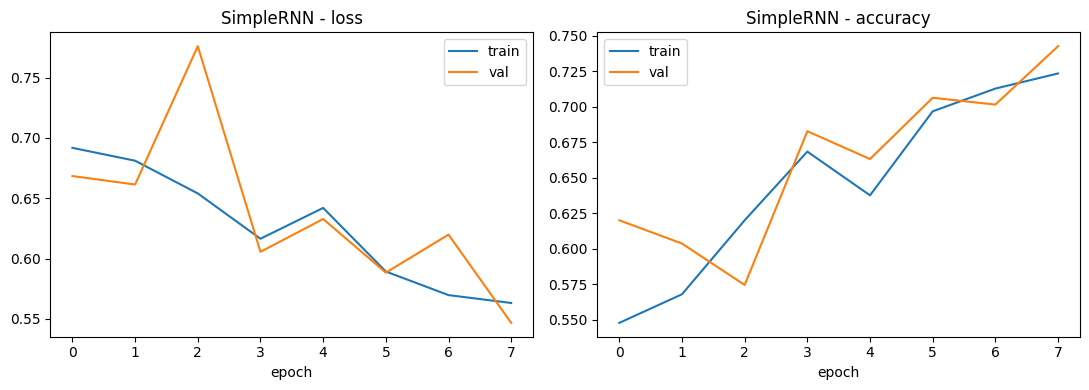

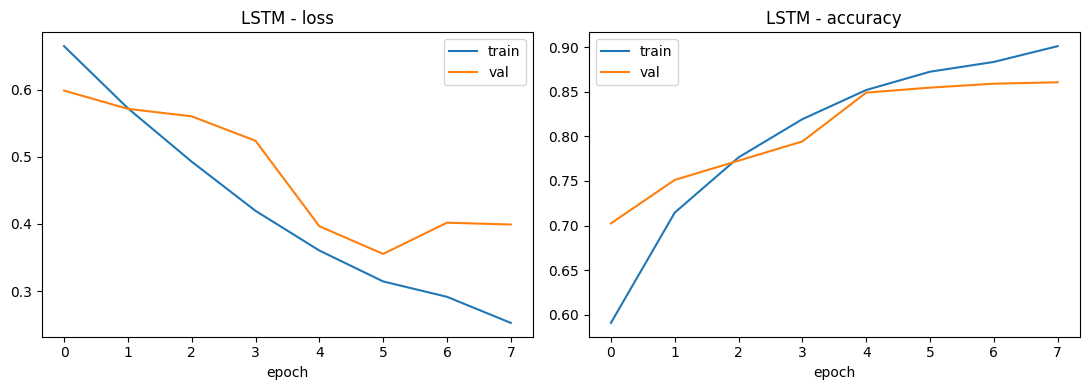

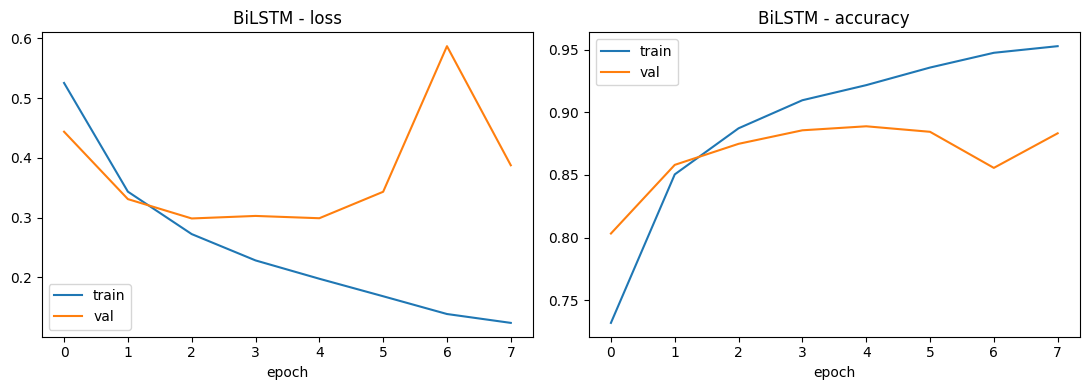

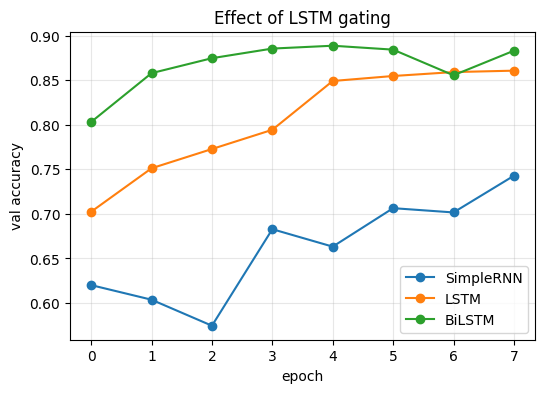

In [7]:
for name in configs: plot_curves(hists[name], name, f"rnn_curves_{name}.png")

# overlay of validation accuracy to show the effect of gating
plt.figure(figsize=(6, 4))
for n, h in hists.items(): plt.plot(h["val_acc"], marker="o", label=n)
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.title("Effect of LSTM gating"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(OUT / "rnn_val_comparison.png", dpi=130); plt.show()

## 4. Test-set evaluation

In [8]:
import pandas as pd
rows, res_all = [], {}
for n, m in models.items():
    r, p, y = report(m, test_dl)
    r.update(train_time_s=times[n], params=n_params(m)); res_all[n] = r
    rows.append(dict(model=n, **{k: round(v, 4) for k, v in r.items()}))
display(pd.DataFrame(rows))
save_result("RNN", dict(res_all["LSTM"], simple_rnn=res_all["SimpleRNN"], bilstm=res_all["BiLSTM"]))

,model,accuracy,precision,recall,f1,train_time_s,params
0,SimpleRNN,0.7362,0.7604,0.6898,0.7234,8.2752,2593282
1,LSTM,0.8473,0.8232,0.8846,0.8528,15.0475,2692354
2,BiLSTM,0.8693,0.8596,0.8829,0.8711,22.9350,2824706


In [9]:
# qualitative check on hand-written reviews
def predict(model, text):
    model.eval()
    with torch.no_grad():
        x = torch.tensor(encode([text])).to(device)
        return torch.softmax(model(x), 1)[0, 1].item()
for t in ["An absolute masterpiece, brilliant acting and a moving story.",
          "Boring, predictable and badly acted. A complete waste of time.",
          "I expected to hate it, but it was surprisingly good."]:
    print({n: round(predict(m, t), 3) for n, m in models.items()}, "|", t)

{'SimpleRNN': 0.875, 'LSTM': 0.94, 'BiLSTM': 1.0} | An absolute masterpiece, brilliant acting and a moving story.
{'SimpleRNN': 0.078, 'LSTM': 0.022, 'BiLSTM': 0.0} | Boring, predictable and badly acted. A complete waste of time.
{'SimpleRNN': 0.869, 'LSTM': 0.899, 'BiLSTM': 1.0} | I expected to hate it, but it was surprisingly good.


## 5. Discussion
- **SimpleRNN** struggles on 256-step sequences: gradients vanish through repeated multiplication by the recurrent weights, so it learns slowly/unstably and cannot carry sentiment cues across long reviews.
- **LSTM gating** (input/forget/output gates + a cell state with additive updates) gives a gradient path that survives many steps, producing a clear accuracy gain at ~4x the parameters in the recurrent layer and slower training.
- **BiLSTM** reads context from both directions; a further ~2 points of accuracy for ~1.5x the LSTM's training time. Its validation loss also starts rising after epoch 5 (over-fitting), so early stopping matters more for the larger model.
- RNNs suit *ordered* data where earlier tokens affect later meaning - text, sensor and financial series.